In [1]:
#setup
import os, time, json, glob, random
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             matthews_corrcoef, classification_report, confusion_matrix, roc_curve, auc,
                             precision_recall_curve, average_precision_score)
from sklearn.preprocessing import label_binarize

# ---- settings: keep IDENTICAL to Notebook 1 (fair comparison) ----
BATCH, EPOCHS, PATIENCE = 128, 30, 7
LR, WD = 1e-3, 1e-4
USE_COSINE = False       # set True ONLY if you added the cosine LR schedule in Notebook 1
SEEDS = [42, 7, 123]     # 3 seeds: judge the attention gain against run-to-run noise
RUN_SE = True            # optional SE-only (channel-only) row: a preview of the Task 3 ablation
NUM_CLASSES = 8

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
for d in ["models", "results", "figures"]:
    os.makedirs(d, exist_ok=True)
print("Device:", device)

Device: cuda


In [2]:
#load Notebook 1 outputs
def find(name, must=""):
    c = glob.glob(f"/kaggle/input/**/{name}", recursive=True) + [name]
    c = [p for p in c if os.path.exists(p) and must in p]
    if not c:
        raise FileNotFoundError(f"{name} not found: run Notebook 1 and add its output as input to this notebook")
    return c[0]

d = np.load(find("bloodmnist_64_clean.npz"))
X, y, split = d["X"], d["y"], d["split"]
X_train, y_train = X[split == "train"], y[split == "train"]
X_val,   y_val   = X[split == "val"],   y[split == "val"]
X_test,  y_test  = X[split == "test"],  y[split == "test"]

norm = json.load(open(find("normalization.json")))            # train-only statistics from Notebook 1
MEAN = torch.tensor(norm["mean"], dtype=torch.float32).view(3, 1, 1)
STD  = torch.tensor(norm["std"],  dtype=torch.float32).view(3, 1, 1)
class_weights = torch.tensor(np.load(find("class_weights.npy")), dtype=torch.float32)
label_map = json.load(open(find("label_map.json")))
class_names = [label_map[str(i)] for i in range(NUM_CLASSES)]

print("Train/Val/Test:", len(y_train), len(y_val), len(y_test), "(should match Notebook 1)")
print("Class weights:", class_weights.numpy().round(3))

Train/Val/Test: 11951 1712 3421 (should match Notebook 1)
Class weights: [1.762 0.686 1.377 0.737 1.76  1.504 0.641 0.909]


In [3]:
#data pipeline (same as Notebook 1)
class BloodDataset(Dataset):
    """Uint8 HWC arrays -> normalized CHW tensors. Augmentation only when train=True."""
    def __init__(self, X, y, train=False):
        self.X, self.y, self.train = X, y, train
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        img = torch.from_numpy(self.X[i]).permute(2, 0, 1).float() / 255.0
        if self.train:
            if random.random() < 0.5: img = torch.flip(img, [2])
            if random.random() < 0.5: img = torch.flip(img, [1])
            img = torch.rot90(img, random.randint(0, 3), [1, 2])
            b = random.uniform(-0.08, 0.08)
            c = random.uniform(0.9, 1.1)
            m = img.mean()
            img = ((img - m) * c + m + b).clamp(0, 1)
        img = (img - MEAN) / STD
        return img, int(self.y[i])

def make_train_loader(seed):
    g = torch.Generator(); g.manual_seed(seed)      # same data order for every model with the same seed
    return DataLoader(BloodDataset(X_train, y_train, train=True), batch_size=BATCH,
                      shuffle=True, generator=g, num_workers=2, pin_memory=True)

val_loader  = DataLoader(BloodDataset(X_val,  y_val),  batch_size=256, num_workers=2, pin_memory=True)
test_loader = DataLoader(BloodDataset(X_test, y_test), batch_size=256, num_workers=2, pin_memory=True)

In [4]:
#models (control = Simple CNN, proposed = same CNN + CBAM)
class SE(nn.Module):                      # channel attention only (optional ablation row)
    def __init__(self, c, r=16):
        super().__init__()
        h = max(c // r, 4)
        self.fc = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Conv2d(c, h, 1), nn.ReLU(True),
                                nn.Conv2d(h, c, 1), nn.Sigmoid())
    def forward(self, x): return x * self.fc(x)

class ChannelAtt(nn.Module):              # CBAM part 1: WHAT to look at
    def __init__(self, c, r=16):
        super().__init__()
        h = max(c // r, 4)
        self.mlp = nn.Sequential(nn.Conv2d(c, h, 1, bias=False), nn.ReLU(True), nn.Conv2d(h, c, 1, bias=False))
    def forward(self, x):
        a = self.mlp(F.adaptive_avg_pool2d(x, 1)) + self.mlp(F.adaptive_max_pool2d(x, 1))
        return x * torch.sigmoid(a)

class SpatialAtt(nn.Module):              # CBAM part 2: WHERE to look
    def __init__(self, k=7):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, k, padding=k // 2, bias=False)
    def forward(self, x):
        a = torch.cat([x.mean(1, keepdim=True), x.amax(1, keepdim=True)], 1)
        return x * torch.sigmoid(self.conv(a))

class CBAM(nn.Module):                    # channel attention, then spatial attention
    def __init__(self, c, r=16, k=7):
        super().__init__()
        self.ca, self.sa = ChannelAtt(c, r), SpatialAtt(k)
    def forward(self, x): return self.sa(self.ca(x))

class AttnSimpleCNN(nn.Module):
    """Notebook 1 Simple CNN (4 blocks: Conv-BN-ReLU-MaxPool). att=None is exactly that baseline;
    att='cbam' inserts CBAM after the ReLU of every block. Nothing else changes."""
    def __init__(self, att=None, num_classes=8, widths=(32, 64, 128, 256), r=16, k=7):
        super().__init__()
        layers, cin = [], 3
        for w in widths:
            layers += [nn.Conv2d(cin, w, 3, padding=1), nn.BatchNorm2d(w), nn.ReLU(inplace=True)]
            if att == "cbam": layers.append(CBAM(w, r, k))
            elif att == "se": layers.append(SE(w, r))
            layers.append(nn.MaxPool2d(2)); cin = w
        self.features = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(widths[-1], num_classes))
    def forward(self, x): return self.head(self.pool(self.features(x)).flatten(1))

ATT = {"SimpleCNN": None, "SimpleCNN_SE": "se", "Proposed_CBAM_CNN": "cbam"}
def build_model(name): return AttnSimpleCNN(ATT[name], NUM_CLASSES)
def count_params(m): return sum(p.numel() for p in m.parameters())

for n in ATT:
    m = build_model(n)
    assert m(torch.zeros(2, 3, 64, 64)).shape == (2, NUM_CLASSES)
    print(f"{n:18s} params {count_params(m):,}")

SimpleCNN          params 391,432
SimpleCNN_SE       params 402,952
Proposed_CBAM_CNN  params 402,832


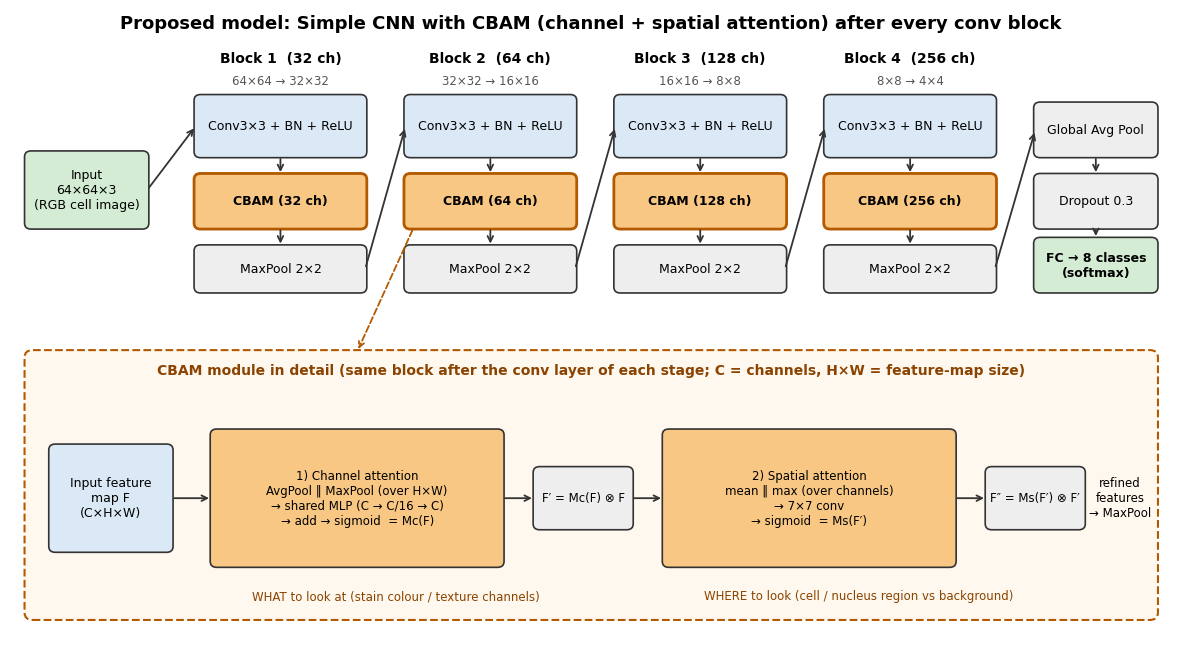

In [5]:
#(A) architecture diagram
import matplotlib.patches as mp

def box(ax, x, y, w, h, text, fc, ec="#333333", fs=9, bold=False, lw=1.2):
    ax.add_patch(mp.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=fc, ec=ec, lw=lw))
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=fs, fontweight="bold" if bold else "normal")
def arrow(ax, x1, y1, x2, y2, color="#333333", ls="-"):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", lw=1.3, color=color, linestyle=ls))

BLUE, ORANGE, GREEN, GREY = "#dbe9f6", "#f9c784", "#d5ecd4", "#eeeeee"
fig, ax = plt.subplots(figsize=(15, 8.2)); ax.set_xlim(0, 14.4); ax.set_ylim(0, 8.4); ax.axis("off")
ax.text(7.2, 8.15, "Proposed model: Simple CNN with CBAM (channel + spatial attention) after every conv block",
        ha="center", fontsize=13, fontweight="bold")
box(ax, 0.2, 5.5, 1.5, 1.0, "Input\n64×64×3\n(RGB cell image)", GREEN)
stages = [(32, "64×64 → 32×32"), (64, "32×32 → 16×16"), (128, "16×16 → 8×8"), (256, "8×8 → 4×4")]
for i, (c, sz) in enumerate(stages):
    x = 2.3 + i * 2.6
    ax.text(x + 1.05, 7.7, f"Block {i+1}  ({c} ch)", ha="center", fontsize=10, fontweight="bold")
    ax.text(x + 1.05, 7.4, sz, ha="center", fontsize=8.5, color="#555555")
    box(ax, x, 6.45, 2.1, 0.8, "Conv3×3 + BN + ReLU", BLUE)
    box(ax, x, 5.5, 2.1, 0.7, f"CBAM ({c} ch)", ORANGE, bold=True, ec="#b35900", lw=2)
    box(ax, x, 4.65, 2.1, 0.6, "MaxPool 2×2", GREY)
    arrow(ax, x + 1.05, 6.45, x + 1.05, 6.2); arrow(ax, x + 1.05, 5.5, x + 1.05, 5.25)
    if i == 0: arrow(ax, 1.7, 6.0, x, 6.85)
    if i > 0:  arrow(ax, x - 0.5, 4.95, x, 6.85)
hx = 12.7
box(ax, hx, 6.45, 1.5, 0.7, "Global Avg Pool", GREY); box(ax, hx, 5.5, 1.5, 0.7, "Dropout 0.3", GREY)
box(ax, hx, 4.65, 1.5, 0.7, "FC → 8 classes\n(softmax)", GREEN, bold=True)
arrow(ax, 12.2, 4.95, hx, 6.8); arrow(ax, hx + 0.75, 6.45, hx + 0.75, 6.2); arrow(ax, hx + 0.75, 5.5, hx + 0.75, 5.35)

ax.add_patch(mp.FancyBboxPatch((0.2, 0.3), 14.0, 3.55, boxstyle="round,pad=0.02,rounding_size=0.1",
                               fc="#fff8ee", ec="#b35900", lw=1.5, ls="--"))
ax.text(7.2, 3.55, "CBAM module in detail (same block after the conv layer of each stage; C = channels, H×W = feature-map size)",
        ha="center", fontsize=10, fontweight="bold", color="#8a4300")
box(ax, 0.5, 1.2, 1.5, 1.4, "Input feature\nmap F\n(C×H×W)", BLUE)
box(ax, 2.5, 1.0, 3.6, 1.8, "1) Channel attention\nAvgPool ‖ MaxPool (over H×W)\n→ shared MLP (C → C/16 → C)\n→ add → sigmoid  = Mc(F)", ORANGE, fs=8.5)
box(ax, 6.5, 1.5, 1.2, 0.8, "F′ = Mc(F) ⊗ F", GREY, fs=8.5)
box(ax, 8.1, 1.0, 3.6, 1.8, "2) Spatial attention\nmean ‖ max (over channels)\n→ 7×7 conv\n→ sigmoid  = Ms(F′)", ORANGE, fs=8.5)
box(ax, 12.1, 1.5, 1.2, 0.8, "F″ = Ms(F′) ⊗ F′", GREY, fs=8.5)
ax.text(13.75, 1.9, "refined\nfeatures\n→ MaxPool", ha="center", va="center", fontsize=8.5)
arrow(ax, 2.0, 1.9, 2.5, 1.9); arrow(ax, 6.1, 1.9, 6.5, 1.9); arrow(ax, 7.7, 1.9, 8.1, 1.9); arrow(ax, 11.7, 1.9, 12.1, 1.9)
ax.text(3.0, 0.55, "WHAT to look at (stain colour / texture channels)", fontsize=8.5, color="#8a4300")
ax.text(8.6, 0.55, "WHERE to look (cell / nucleus region vs background)", fontsize=8.5, color="#8a4300")
arrow(ax, 5.0, 5.5, 4.3, 3.85, color="#b35900", ls="--")
plt.savefig("figures/proposed_architecture.png", dpi=200, bbox_inches="tight"); plt.show()

## (B) Attention type and why
**Type: hybrid attention, CBAM (channel attention followed by spatial attention).**
- **Channel attention (what):** the Task 1 EDA showed that stain colour and texture differ between classes (e.g. platelets are the brightest and lowest-contrast objects, monocytes have the lowest green level), so colour/texture channels carry class information. Channel attention re-weights the feature channels.
- **Spatial attention (where):** each image is a small 64x64 crop with one centred cell on a plain background, and some classes are tiny (platelets) or look alike (immature granulocytes vs monocytes, erythroblast vs lymphocyte). Spatial attention can highlight the cell/nucleus region and suppress the background.
- **Light-weight:** CBAM adds about 11k parameters to a 0.39M-parameter CNN, so a gain cannot be explained by "a bigger model".
- **Controlled comparison:** the control is exactly the Notebook 1 Simple CNN; the only change is the attention module.
These are expectations, not results; the results below confirm or reject them.

## (C) Explanation in plain words
> DRAFT: rewrite in the group's own words (brief Section 6.5: not copied from a paper).

**Step by step.** (1) The 64x64 RGB image passes through four blocks. Each block has a convolution (detects local patterns such as edges, granules, nucleus shape), batch normalisation and ReLU. (2) CBAM then re-weights the block's output. Channel attention squeezes every feature map to one number with average and max pooling, passes both through the same small two-layer network, adds the results and applies a sigmoid, giving a 0-1 weight per feature map; useful maps are turned up, useless ones down. (3) Spatial attention takes the average and maximum across channels at every pixel, applies a 7x7 convolution and a sigmoid, and gives a 0-1 weight per pixel position, so the cell region is emphasised and the plain background suppressed. (4) Max-pooling halves the image size and the next block repeats this with more channels (32, 64, 128, 256). (5) Global average pooling, dropout (0.3) and a linear layer give 8 class scores.

**Why each part exists.** Convolutions learn visual patterns; batch norm stabilises training; max-pooling gives tolerance to small shifts and saves computation; channel attention chooses which patterns matter; spatial attention chooses where to look; dropout and class-weighted loss reduce over-fitting and class imbalance.

**Why it should beat the baselines.** Against the same CNN without attention, CBAM gives a cheap way to focus on the cell and its stain pattern, which should help the hard look-alike classes. This is a hypothesis that the numbers test. Against the larger baselines (ResNet50, DenseNet121, MobileNetV2) we make no such claim in advance; if a baseline is better, we report it honestly.

In [6]:
#settings table
settings = pd.DataFrame([
    ("Backbone", "Notebook 1 Simple CNN: 4 blocks of Conv3x3-BN-ReLU-MaxPool2x2, widths 32/64/128/256, global avg pool, Dropout 0.3, FC 8"),
    ("Attention (proposed)", "CBAM after the ReLU of every block: channel (r=16, avg+max pool, shared MLP) then spatial (7x7 conv)"),
    ("Controls", "Same CNN without attention (= Notebook 1 baseline); optional same CNN with SE (channel-only)"),
    ("Input / init", "64x64x3, train-only mean/std; all models trained from scratch"),
    ("Augmentation", "H/V flip, random 90-degree rotation, mild brightness/contrast (train only)"),
    ("Loss / imbalance", "class-weighted cross-entropy (weights from the train split)"),
    ("Optimiser", f"AdamW, lr {LR}, weight decay {WD}" + (", cosine schedule" if USE_COSINE else ", constant lr")),
    ("Epochs / batch", f"max {EPOCHS}, early stopping patience {PATIENCE} on validation macro-F1 / {BATCH}"),
    ("Model selection", "best epoch by validation macro-F1; test set used only for the final evaluation"),
    ("Seeds", f"{SEEDS} (same data order for every model with the same seed); mixed precision on GPU"),
], columns=["Setting", "Value"])
display(settings); settings.to_csv("results/proposed_model_settings.csv", index=False)

,Setting,Value
0,Backbone,Notebook 1 Simple CNN: 4 blocks of Conv3x3-BN-...
1,Attention (proposed),CBAM after the ReLU of every block: channel (r...
2,Controls,Same CNN without attention (= Notebook 1 basel...
3,Input / init,"64x64x3, train-only mean/std; all models train..."
4,Augmentation,"H/V flip, random 90-degree rotation, mild brig..."
5,Loss / imbalance,class-weighted cross-entropy (weights from the...
6,Optimiser,"AdamW, lr 0.001, weight decay 0.0001, constant lr"
7,Epochs / batch,"max 30, early stopping patience 7 on validatio..."
8,Model selection,best epoch by validation macro-F1; test set us...
9,Seeds,"[42, 7, 123] (same data order for every model ..."


In [7]:
#training and evaluation functions
def evaluate(model, loader):
    model.eval(); probs, ys = [], []
    with torch.no_grad():
        for xb, yb in loader:
            with torch.autocast(device_type=device.type, enabled=use_amp):
                out = model(xb.to(device, non_blocking=True))
            probs.append(F.softmax(out.float(), dim=1).cpu().numpy()); ys.append(yb.numpy())
    probs, ys = np.concatenate(probs), np.concatenate(ys)
    return ys, probs.argmax(1), probs

def train_model(name, seed, show=True):
    set_seed(seed)
    model = build_model(name).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS) if USE_COSINE else None
    crit = nn.CrossEntropyLoss(weight=class_weights.to(device))
    scaler = torch.amp.GradScaler(device.type, enabled=use_amp)
    loader = make_train_loader(seed)
    best_f1, best_state, wait, best_ep, hist = -1.0, None, 0, 0, []
    t0 = time.time()
    for ep in range(1, EPOCHS + 1):
        model.train(); running = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                loss = crit(model(xb), yb)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            running += loss.item() * len(yb)
        if sched: sched.step()
        yv, pv, _ = evaluate(model, val_loader)
        vf1 = f1_score(yv, pv, average="macro")
        hist.append({"epoch": ep, "train_loss": running / len(y_train), "val_macro_f1": vf1})
        if show: print(f"[{name} s{seed}] epoch {ep:02d} | loss {running/len(y_train):.4f} | val macro-F1 {vf1:.4f}")
        if vf1 > best_f1:
            best_f1, wait, best_ep = vf1, 0, ep
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= PATIENCE:
                if show: print(f"[{name} s{seed}] early stop at epoch {ep}")
                break
    train_time = time.time() - t0
    model.load_state_dict(best_state)
    path = f"models/{name}_s{seed}_best.pth"; torch.save(best_state, path)
    info = {"model": name, "seed": seed, "params_M": count_params(model) / 1e6,
            "size_MB": os.path.getsize(path) / 1e6, "train_time_min": train_time / 60,
            "epochs_run": len(hist), "best_epoch": best_ep, "best_val_macro_f1": best_f1}
    return model, pd.DataFrame(hist), info

def metrics_row(info, yt, yp, pr):
    Yb = label_binarize(yt, classes=list(range(NUM_CLASSES)))
    return {**info, "init": "scratch",
            "test_acc": accuracy_score(yt, yp),
            "macro_precision": precision_score(yt, yp, average="macro"),
            "macro_recall": recall_score(yt, yp, average="macro"),
            "macro_f1": f1_score(yt, yp, average="macro"),
            "weighted_precision": precision_score(yt, yp, average="weighted"),
            "weighted_recall": recall_score(yt, yp, average="weighted"),
            "weighted_f1": f1_score(yt, yp, average="weighted"),
            "macro_auc_ovr": roc_auc_score(yt, pr, multi_class="ovr", average="macro"),
            "macro_pr_auc": average_precision_score(Yb, pr, average="macro"),
            "mcc": matthews_corrcoef(yt, yp)}

def report_model(tag, yt, yp, pr):
    print("=" * 70, f"\n{tag}\n", "=" * 70)
    print(classification_report(yt, yp, target_names=class_names, digits=4))
    Yb = label_binarize(yt, classes=list(range(NUM_CLASSES)))
    fig, axes = plt.subplots(1, 3, figsize=(21, 6))
    sns.heatmap(confusion_matrix(yt, yp), annot=True, fmt="d", cmap="Blues", xticklabels=class_names,
                yticklabels=class_names, ax=axes[0], cbar=False)
    axes[0].set(title=f"{tag}: confusion matrix (test)", xlabel="Predicted class", ylabel="True class")
    axes[0].tick_params(axis="x", rotation=45)
    for c in range(NUM_CLASSES):
        fpr, tpr, _ = roc_curve(Yb[:, c], pr[:, c])
        axes[1].plot(fpr, tpr, label=f"{class_names[c]} (AUC={auc(fpr, tpr):.3f})")
        p, r, _ = precision_recall_curve(Yb[:, c], pr[:, c])
        axes[2].plot(r, p, label=f"{class_names[c]} (AP={average_precision_score(Yb[:, c], pr[:, c]):.3f})")
    axes[1].plot([0, 1], [0, 1], "k--", lw=0.8)
    axes[1].set(title=f"{tag}: ROC curves, one-vs-rest", xlabel="False positive rate", ylabel="True positive rate")
    axes[2].set(title=f"{tag}: precision-recall curves, one-vs-rest", xlabel="Recall", ylabel="Precision")
    axes[1].legend(fontsize=8, loc="lower right"); axes[2].legend(fontsize=8, loc="lower left")
    plt.tight_layout(); plt.savefig(f"figures/{tag}_cm_roc_pr.png", dpi=200, bbox_inches="tight"); plt.show()

[SimpleCNN s42] epoch 01 | loss 0.6169 | val macro-F1 0.8616
[SimpleCNN s42] epoch 02 | loss 0.2679 | val macro-F1 0.9253
[SimpleCNN s42] epoch 03 | loss 0.2049 | val macro-F1 0.9265
[SimpleCNN s42] epoch 04 | loss 0.1658 | val macro-F1 0.6360
[SimpleCNN s42] epoch 05 | loss 0.1489 | val macro-F1 0.9647
[SimpleCNN s42] epoch 06 | loss 0.1200 | val macro-F1 0.8891
[SimpleCNN s42] epoch 07 | loss 0.1104 | val macro-F1 0.8805
[SimpleCNN s42] epoch 08 | loss 0.1225 | val macro-F1 0.9461
[SimpleCNN s42] epoch 09 | loss 0.0869 | val macro-F1 0.9568
[SimpleCNN s42] epoch 10 | loss 0.0887 | val macro-F1 0.9626
[SimpleCNN s42] epoch 11 | loss 0.0948 | val macro-F1 0.9305
[SimpleCNN s42] epoch 12 | loss 0.0853 | val macro-F1 0.9440
[SimpleCNN s42] early stop at epoch 12
SimpleCNN_s42
                       precision    recall  f1-score   support

             basophil     0.9714    0.9754    0.9734       244
           eosinophil     0.9968    0.9984    0.9976       624
         erythroblast    

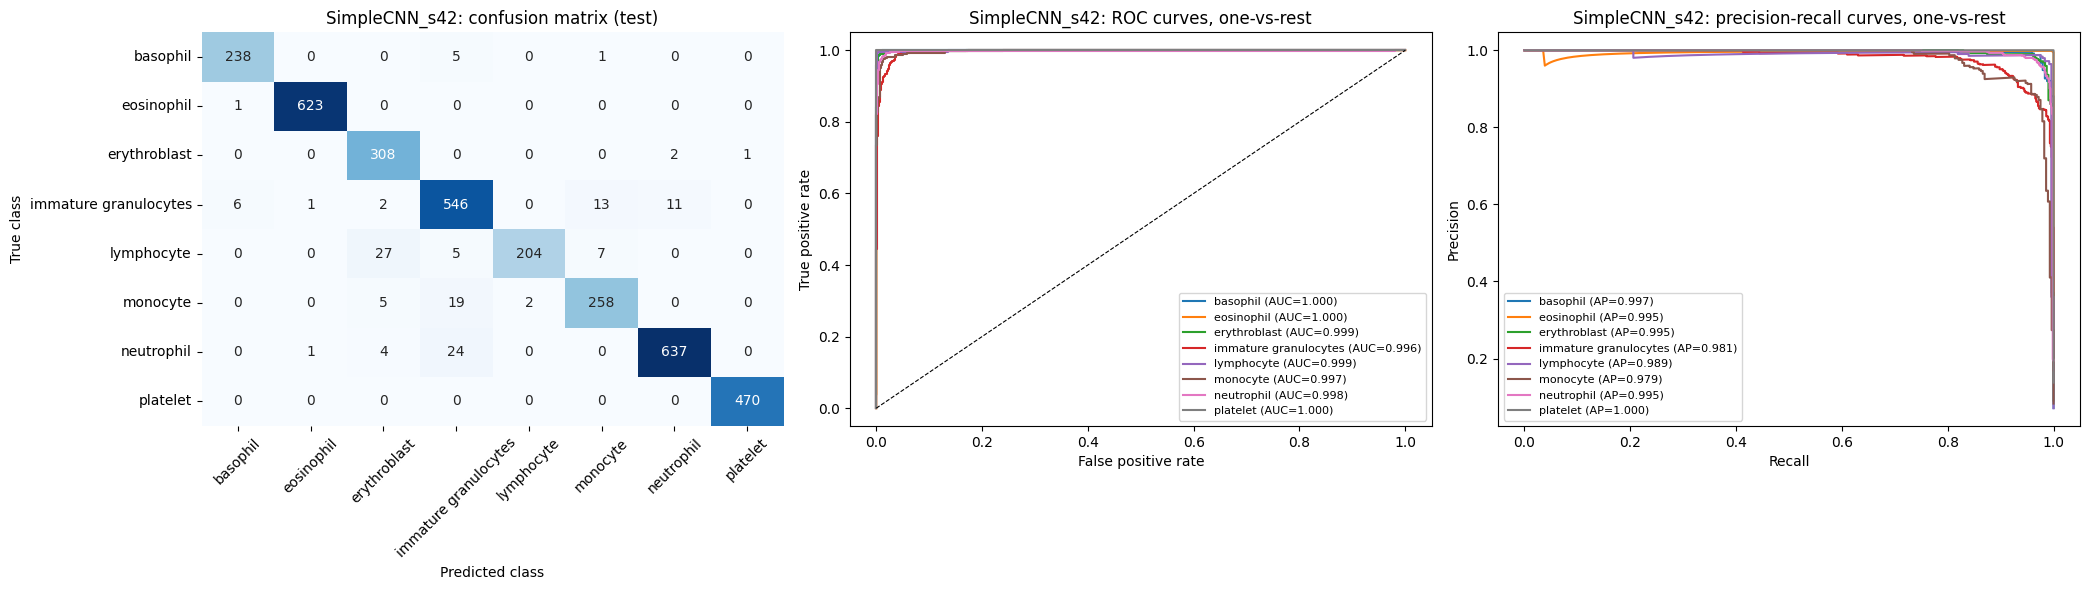

==> SimpleCNN_s42: val macro-F1 0.9647 | test macro-F1 0.9535 | 0.6 min
[Proposed_CBAM_CNN s42] epoch 01 | loss 0.6305 | val macro-F1 0.7311
[Proposed_CBAM_CNN s42] epoch 02 | loss 0.2218 | val macro-F1 0.8185
[Proposed_CBAM_CNN s42] epoch 03 | loss 0.1770 | val macro-F1 0.9223
[Proposed_CBAM_CNN s42] epoch 04 | loss 0.1273 | val macro-F1 0.8666
[Proposed_CBAM_CNN s42] epoch 05 | loss 0.1115 | val macro-F1 0.8969
[Proposed_CBAM_CNN s42] epoch 06 | loss 0.0978 | val macro-F1 0.9179
[Proposed_CBAM_CNN s42] epoch 07 | loss 0.0852 | val macro-F1 0.9277
[Proposed_CBAM_CNN s42] epoch 08 | loss 0.0914 | val macro-F1 0.9742
[Proposed_CBAM_CNN s42] epoch 09 | loss 0.0756 | val macro-F1 0.9774
[Proposed_CBAM_CNN s42] epoch 10 | loss 0.0666 | val macro-F1 0.8737
[Proposed_CBAM_CNN s42] epoch 11 | loss 0.0681 | val macro-F1 0.9683
[Proposed_CBAM_CNN s42] epoch 12 | loss 0.0670 | val macro-F1 0.9423
[Proposed_CBAM_CNN s42] epoch 13 | loss 0.0572 | val macro-F1 0.9092
[Proposed_CBAM_CNN s42] epoch 1

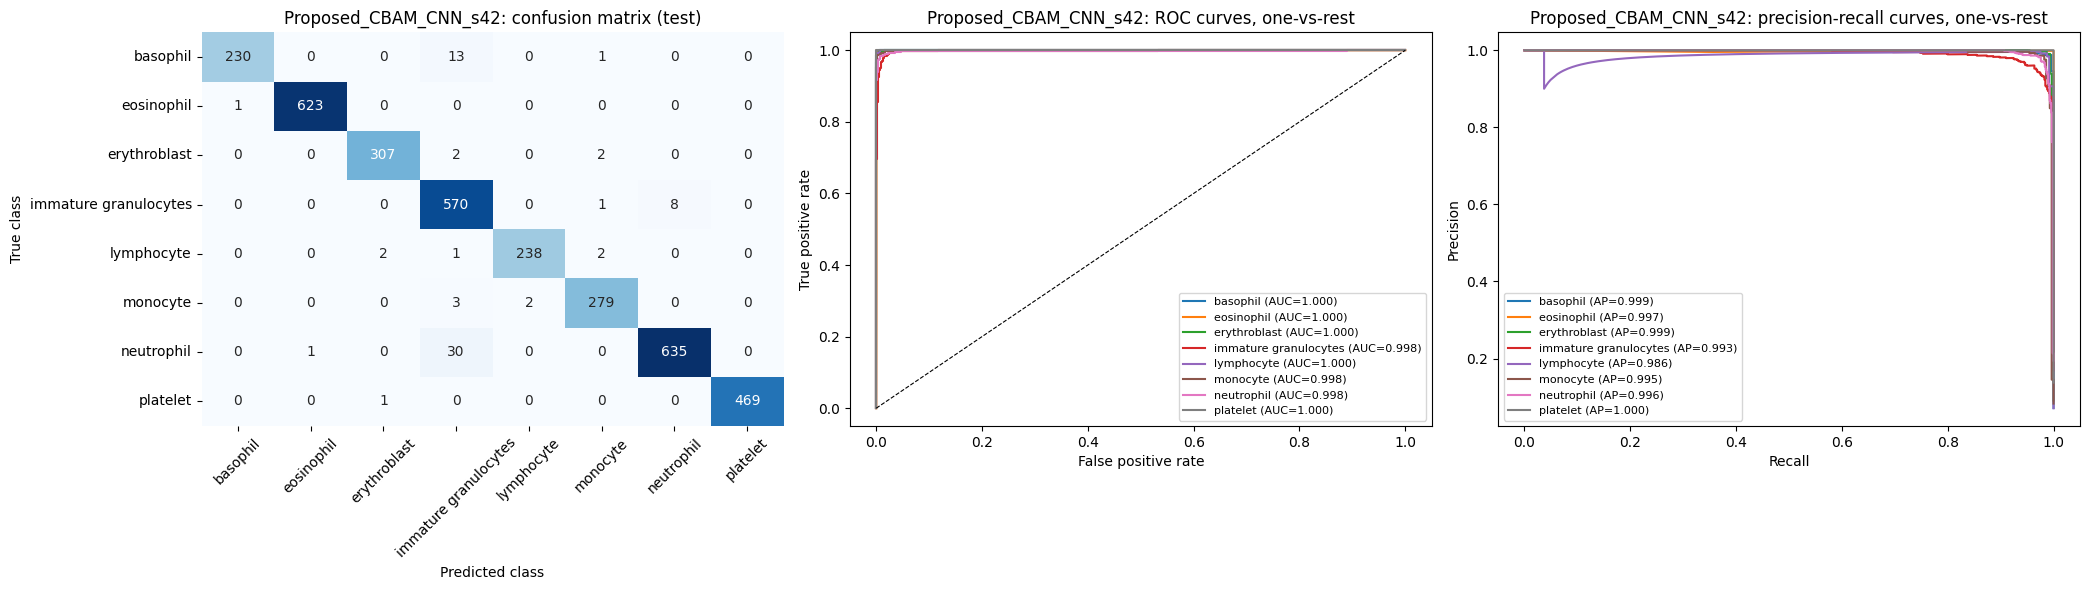

==> Proposed_CBAM_CNN_s42: val macro-F1 0.9875 | test macro-F1 0.9803 | 1.6 min
[SimpleCNN_SE s42] epoch 01 | loss 0.6579 | val macro-F1 0.7631
[SimpleCNN_SE s42] epoch 02 | loss 0.2505 | val macro-F1 0.9075
[SimpleCNN_SE s42] epoch 03 | loss 0.1794 | val macro-F1 0.9342
[SimpleCNN_SE s42] epoch 04 | loss 0.1416 | val macro-F1 0.7904
[SimpleCNN_SE s42] epoch 05 | loss 0.1434 | val macro-F1 0.8602
[SimpleCNN_SE s42] epoch 06 | loss 0.1118 | val macro-F1 0.9232
[SimpleCNN_SE s42] epoch 07 | loss 0.0943 | val macro-F1 0.8372
[SimpleCNN_SE s42] epoch 08 | loss 0.1090 | val macro-F1 0.9469
[SimpleCNN_SE s42] epoch 09 | loss 0.0798 | val macro-F1 0.9340
[SimpleCNN_SE s42] epoch 10 | loss 0.0789 | val macro-F1 0.9458
[SimpleCNN_SE s42] epoch 11 | loss 0.0769 | val macro-F1 0.9735
[SimpleCNN_SE s42] epoch 12 | loss 0.0698 | val macro-F1 0.9777
[SimpleCNN_SE s42] epoch 13 | loss 0.0710 | val macro-F1 0.9312
[SimpleCNN_SE s42] epoch 14 | loss 0.0734 | val macro-F1 0.9045
[SimpleCNN_SE s42] epoch

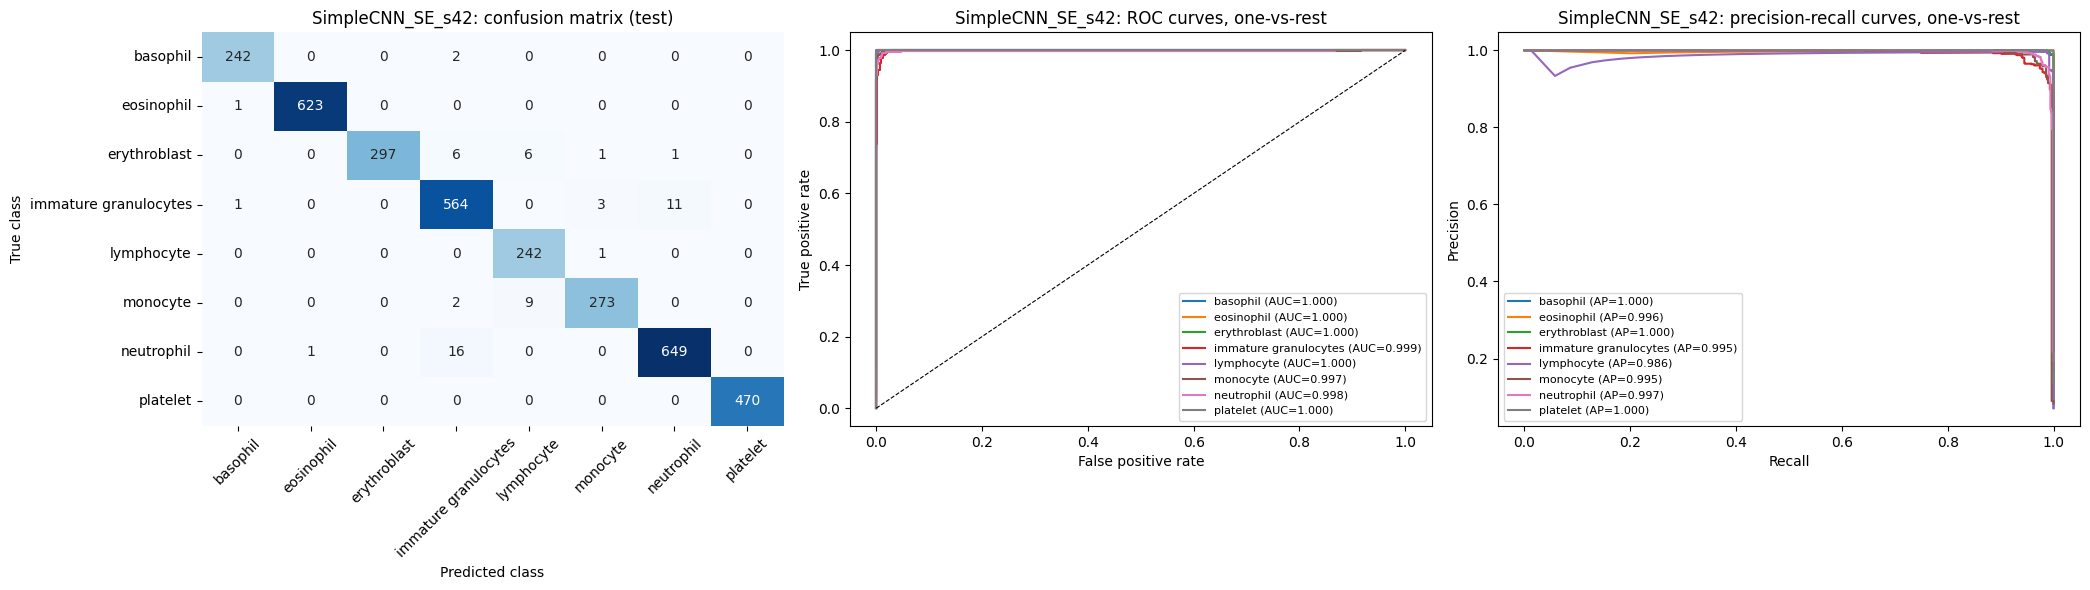

==> SimpleCNN_SE_s42: val macro-F1 0.9854 | test macro-F1 0.9812 | 1.2 min
==> SimpleCNN_s7: val macro-F1 0.9807 | test macro-F1 0.9749 | 0.8 min
==> Proposed_CBAM_CNN_s7: val macro-F1 0.9782 | test macro-F1 0.9720 | 1.0 min
==> SimpleCNN_SE_s7: val macro-F1 0.9715 | test macro-F1 0.9688 | 0.8 min
==> SimpleCNN_s123: val macro-F1 0.9774 | test macro-F1 0.9784 | 0.8 min
==> Proposed_CBAM_CNN_s123: val macro-F1 0.9822 | test macro-F1 0.9807 | 1.3 min
==> SimpleCNN_SE_s123: val macro-F1 0.9805 | test macro-F1 0.9812 | 0.6 min


In [8]:
#train all models over 3 seeds
MODELS2 = ["SimpleCNN", "Proposed_CBAM_CNN"] + (["SimpleCNN_SE"] if RUN_SE else [])
RUNS, HIST, PC_F1, PC_REC = [], {}, {}, {}
for seed in SEEDS:
    for name in MODELS2:
        first = (seed == SEEDS[0])
        model, hist, info = train_model(name, seed, show=first)
        yt, yp, pr = evaluate(model, test_loader)          # test set used ONLY here
        tag = f"{name}_s{seed}"
        RUNS.append(metrics_row(info, yt, yp, pr)); HIST[tag] = hist
        PC_F1[tag]  = f1_score(yt, yp, average=None, labels=list(range(NUM_CLASSES)))
        PC_REC[tag] = recall_score(yt, yp, average=None, labels=list(range(NUM_CLASSES)))
        np.savez_compressed(f"results/proposed_preds_{tag}.npz", y_true=yt, y_pred=yp, probs=pr)   # for McNemar in Task 3
        hist.to_csv(f"results/{tag}_history.csv", index=False)
        if first: report_model(tag, yt, yp, pr)
        print(f"==> {tag}: val macro-F1 {info['best_val_macro_f1']:.4f} | test macro-F1 {RUNS[-1]['macro_f1']:.4f} | {info['train_time_min']:.1f} min")
        del model; torch.cuda.empty_cache()

,test_acc,macro_f1,weighted_f1,macro_auc_ovr,macro_pr_auc,mcc,params_M,size_MB,train_time_min,epochs_run
SimpleCNN,0.9718 +/- 0.0104,0.9689 +/- 0.0135,0.9718 +/- 0.0104,0.9989 +/- 0.0003,0.9937 +/- 0.0019,0.9672 +/- 0.0121,0.391,1.579,0.615,12
Proposed_CBAM_CNN,0.9777 +/- 0.0045,0.9777 +/- 0.0049,0.9777 +/- 0.0045,0.9990 +/- 0.0002,0.9941 +/- 0.0014,0.9740 +/- 0.0053,0.403,1.629,1.635,26
SimpleCNN_SE,0.9770 +/- 0.0070,0.9771 +/- 0.0072,0.9771 +/- 0.0070,0.9990 +/- 0.0002,0.9941 +/- 0.0020,0.9732 +/- 0.0081,0.403,1.630,1.231,30


Macro-F1 difference (CBAM - no attention) per seed: {42: 0.0268, 7: -0.0029, 123: 0.0022}
mean +0.0087 | std 0.0159 | CBAM better in 2 of 3 seeds
Reading: CBAM is higher on average but not in every seed / not beyond the spread: do NOT claim a clear improvement.
Note: 3 seeds and one test set are a first look, not a significance test (McNemar / Wilcoxon are Task 3).
Control check: Notebook 1 Simple CNN macro-F1 0.9535 vs here (seed 42) 0.9535
Per-class recall (mean over seeds):


,SimpleCNN,Proposed_CBAM_CNN,SimpleCNN_SE,CBAM - no attention
basophil,0.9822,0.9645,0.9740,-0.0178
eosinophil,0.9989,0.9995,0.9979,0.0005
erythroblast,0.9850,0.9818,0.9657,-0.0032
immature granulocytes,0.9424,0.9678,0.9660,0.0253
lymphocyte,0.9438,0.9904,0.9945,0.0466
monocyte,0.9425,0.9554,0.9683,0.0129
neutrophil,0.9650,0.9585,0.9545,-0.0065
platelet,1.0000,0.9993,1.0000,-0.0007


Per-class F1 (mean over seeds):


,SimpleCNN,Proposed_CBAM_CNN,SimpleCNN_SE,CBAM - no attention
basophil,0.9789,0.9791,0.9813,0.0002
eosinophil,0.9984,0.9976,0.9981,-0.0008
erythroblast,0.9679,0.9860,0.9809,0.0181
immature granulocytes,0.9439,0.9509,0.9511,0.0069
lymphocyte,0.9502,0.9771,0.9739,0.0269
monocyte,0.9407,0.9609,0.9641,0.0202
neutrophil,0.9718,0.9703,0.9672,-0.0014
platelet,0.9996,0.9993,1.0000,-0.0004


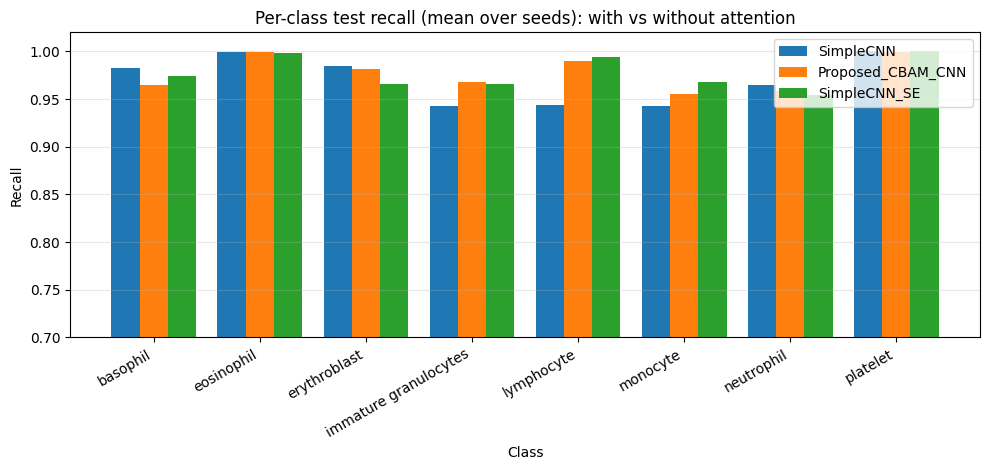

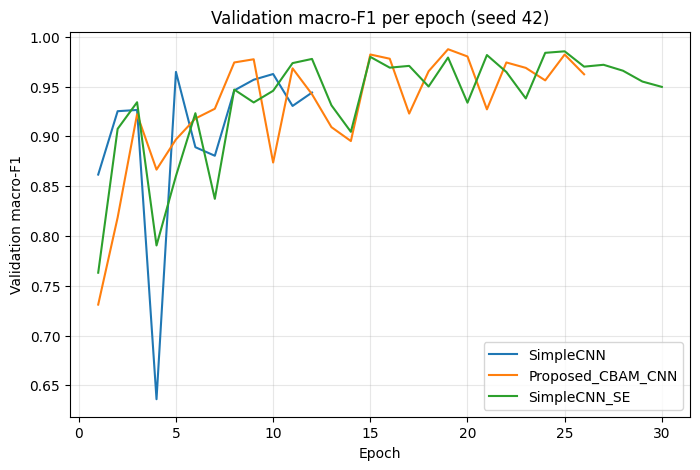

In [9]:
##does attention help? (mean ± std over seeds)
runs = pd.DataFrame(RUNS); runs.round(4).to_csv("results/proposed_all_runs.csv", index=False)
mets = ["test_acc", "macro_f1", "weighted_f1", "macro_auc_ovr", "macro_pr_auc", "mcc"]
g = runs.groupby("model")[mets].agg(["mean", "std"]).reindex(MODELS2)
summ = pd.DataFrame({m: [f"{g[(m,'mean')][k]:.4f} +/- {g[(m,'std')][k]:.4f}" for k in MODELS2] for m in mets}, index=MODELS2)
cost = runs[runs.seed == SEEDS[0]].set_index("model").loc[MODELS2, ["params_M", "size_MB", "train_time_min", "epochs_run"]].round(3)
tbl = pd.concat([summ, cost], axis=1); display(tbl); tbl.to_csv("results/proposed_attention_ablation.csv")

# paired per-seed difference: CBAM minus the same CNN without attention
b = runs[runs.model == "SimpleCNN"].set_index("seed")["macro_f1"]
c = runs[runs.model == "Proposed_CBAM_CNN"].set_index("seed")["macro_f1"]
dl = (c - b).dropna(); sd = dl.std(ddof=1) if len(dl) > 1 else float("nan")
print("Macro-F1 difference (CBAM - no attention) per seed:", {int(k): round(float(v), 4) for k, v in dl.items()})
print(f"mean {dl.mean():+.4f} | std {sd:.4f} | CBAM better in {(dl > 0).sum()} of {len(dl)} seeds")
if (dl > 0).all() and len(dl) > 1 and dl.mean() > sd:
    print("Reading: CBAM is better in every seed and the gain exceeds the seed-to-seed spread: evidence that attention helps on this backbone.")
elif dl.mean() > 0:
    print("Reading: CBAM is higher on average but not in every seed / not beyond the spread: do NOT claim a clear improvement.")
else:
    print("Reading: CBAM did not improve macro-F1 over the same CNN without attention: report this honestly and discuss why.")
print("Note: 3 seeds and one test set are a first look, not a significance test (McNemar / Wilcoxon are Task 3).")

# sanity check: the control at seed 42 should be close to the Notebook 1 Simple CNN
try:
    b1 = pd.read_csv(find("baselines_results.csv")).set_index("model").loc["SimpleCNN", "macro_f1"]
    print(f"Control check: Notebook 1 Simple CNN macro-F1 {b1:.4f} vs here (seed 42) {b[42]:.4f}")
except Exception as e:
    print("control check skipped:", e)

# per-class recall and F1 (mean over seeds)
pcr = pd.DataFrame({m: np.mean([PC_REC[f"{m}_s{s}"] for s in SEEDS], axis=0) for m in MODELS2}, index=class_names)
pcf = pd.DataFrame({m: np.mean([PC_F1[f"{m}_s{s}"] for s in SEEDS], axis=0) for m in MODELS2}, index=class_names)
pcr["CBAM - no attention"] = pcr["Proposed_CBAM_CNN"] - pcr["SimpleCNN"]
pcf["CBAM - no attention"] = pcf["Proposed_CBAM_CNN"] - pcf["SimpleCNN"]
print("Per-class recall (mean over seeds):"); display(pcr.round(4))
print("Per-class F1 (mean over seeds):");     display(pcf.round(4))
pcr.round(4).to_csv("results/proposed_per_class_recall.csv"); pcf.round(4).to_csv("results/proposed_per_class_f1.csv")

fig, ax = plt.subplots(figsize=(10, 4.8)); x = np.arange(NUM_CLASSES); w = 0.8 / len(MODELS2)
for i, m in enumerate(MODELS2): ax.bar(x + i * w - 0.4 + w / 2, pcr[m], w, label=m)
ax.set(title="Per-class test recall (mean over seeds): with vs without attention", xlabel="Class", ylabel="Recall", ylim=(0.7, 1.02))
ax.set_xticks(x); ax.set_xticklabels(class_names, rotation=30, ha="right"); ax.legend(); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig("figures/proposed_per_class_recall.png", dpi=200, bbox_inches="tight"); plt.show()

plt.figure(figsize=(8, 5))
for name in MODELS2: plt.plot(HIST[f"{name}_s{SEEDS[0]}"]["epoch"], HIST[f"{name}_s{SEEDS[0]}"]["val_macro_f1"], label=name)
plt.title(f"Validation macro-F1 per epoch (seed {SEEDS[0]})"); plt.xlabel("Epoch"); plt.ylabel("Validation macro-F1")
plt.legend(); plt.grid(alpha=0.3); plt.savefig("figures/proposed_val_curves.png", dpi=200, bbox_inches="tight"); plt.show()

,model,params_M,size_MB,train_time_min,epochs_run,best_epoch,best_val_macro_f1,init,test_acc,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,macro_auc_ovr
0,Proposed_CBAM_CNN (seed 42),0.4028,1.6292,1.6353,26.0000,19.0000,0.9875,scratch,0.9795,0.9829,0.9782,0.9803,0.9804,0.9795,0.9797,0.9992
1,Proposed_CBAM_CNN (mean of 3 seeds),0.4028,1.6292,1.3031,20.6667,13.6667,0.9826,NaN,0.9777,0.9786,0.9771,0.9777,0.9782,0.9777,0.9777,0.9990
2,MobileNetV2,2.2341,9.1708,2.2858,30.0000,27.0000,0.9721,scratch,0.9734,0.9698,0.9753,0.9722,0.9738,0.9734,0.9732,0.9990
3,ResNet50,23.5167,94.3769,14.2039,14.0000,7.0000,0.9758,scratch,0.9728,0.9750,0.9687,0.9714,0.9734,0.9728,0.9728,0.9989
4,DenseNet121,6.9621,28.4234,2.3252,15.0000,8.0000,0.9672,scratch,0.9702,0.9681,0.9669,0.9672,0.9708,0.9702,0.9703,0.9985
5,SimpleCNN,0.3914,1.5792,0.5186,12.0000,5.0000,0.9647,scratch,0.9600,0.9579,0.9514,0.9535,0.9613,0.9600,0.9599,0.9986


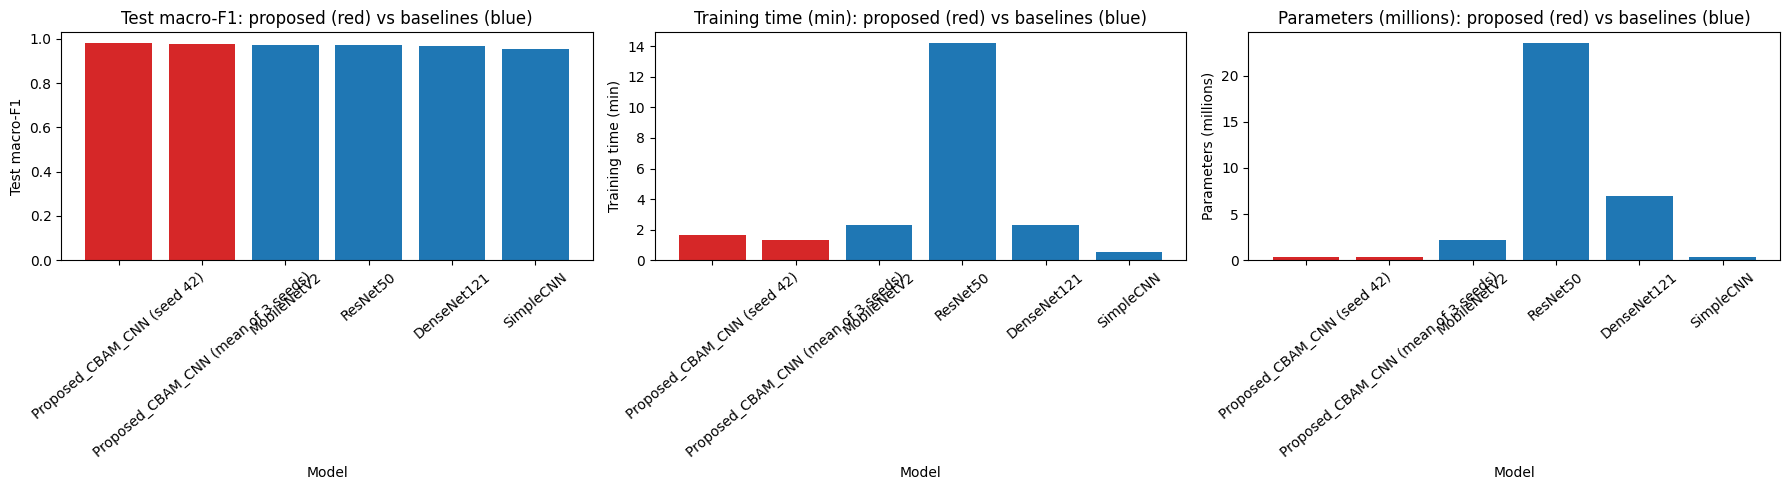

Best baseline (by validation macro-F1): ResNet50 | test macro-F1 0.9714, accuracy 0.9728
Proposed CBAM CNN (seed 42):          test macro-F1 0.9803, accuracy 0.9795
Proposed CBAM CNN (mean of seeds):    test macro-F1 0.9777, accuracy 0.9777
Report this comparison honestly, whichever way it goes. The fair test of attention is the same-backbone comparison above.


In [10]:
#comparison with Notebook 1 baselines
base = pd.read_csv(find("baselines_results.csv"))
p42 = runs[(runs.model == "Proposed_CBAM_CNN") & (runs.seed == SEEDS[0])].copy()
pm = runs[runs.model == "Proposed_CBAM_CNN"].select_dtypes("number").drop(columns=["seed"]).mean().to_frame().T
pm["model"] = f"Proposed_CBAM_CNN (mean of {len(SEEDS)} seeds)"
p42["model"] = "Proposed_CBAM_CNN (seed 42)"
cols = [c for c in base.columns if c in p42.columns]
comp = pd.concat([base[cols], p42[cols], pm[[c for c in cols if c in pm.columns]]], ignore_index=True)
comp = comp.sort_values("macro_f1", ascending=False).reset_index(drop=True)
display(comp.round(4)); comp.round(4).to_csv("results/proposed_vs_baselines.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for a, (col, lab) in zip(axes, [("macro_f1", "Test macro-F1"), ("train_time_min", "Training time (min)"), ("params_M", "Parameters (millions)")]):
    colors = ["tab:red" if str(m).startswith("Proposed") else "tab:blue" for m in comp["model"]]
    a.bar(comp["model"], comp[col], color=colors)
    a.set(title=f"{lab}: proposed (red) vs baselines (blue)", xlabel="Model", ylabel=lab); a.tick_params(axis="x", rotation=40)
plt.tight_layout(); plt.savefig("figures/proposed_vs_baselines.png", dpi=200, bbox_inches="tight"); plt.show()

best_b = base.sort_values("best_val_macro_f1", ascending=False).iloc[0]       # selected by VALIDATION macro-F1
print(f"Best baseline (by validation macro-F1): {best_b['model']} | test macro-F1 {best_b['macro_f1']:.4f}, accuracy {best_b['test_acc']:.4f}")
print(f"Proposed CBAM CNN (seed 42):          test macro-F1 {p42['macro_f1'].iloc[0]:.4f}, accuracy {p42['test_acc'].iloc[0]:.4f}")
print(f"Proposed CBAM CNN (mean of seeds):    test macro-F1 {pm['macro_f1'].iloc[0]:.4f}, accuracy {pm['test_acc'].iloc[0]:.4f}")
print("Report this comparison honestly, whichever way it goes. The fair test of attention is the same-backbone comparison above.")

In [11]:
#!zip -qr proposed_outputs.zip results figures models
print("Saved: results/, figures/, models/ (per-seed checkpoints), per-seed test predictions for Task 3")

Saved: results/, figures/, models/ (per-seed checkpoints), per-seed test predictions for Task 3
